[*********************100%***********************]  2 of 2 completed


=== ANALYSIS 1: DISTRIBUTION & HYPOTHESIS TESTING ===
Total observations: 2739 trading days
Jarque-Bera normality test p-value (SPY): 0.0000e+00 | (GLD): 0.0000e+00
S&P 500 stress threshold (bottom 5%): -1.69%
GLD mean daily return on stress days (n=137): 0.0288%
GLD mean daily return on normal days (n=2602): 0.0427%
Welch's t-test: t = -0.1070, p = 0.9150
Mann-Whitney U test: U = 172663.5, p = 0.5368

=== ANALYSIS 2: OLS REGRESSION & ROLLING CORRELATION ===
Regression equation: r_GLD = 0.00037 + 0.0893 * r_SPY
Correlation (r): 0.0954 | R-squared: 0.0091 | p-value: 0.0000
60-day rolling correlation -> Min: -0.626, Max: 0.804, Mean: 0.045


/tmp/ipykernel_1617/2693202068.py:73: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot([normal_days, stress_days],


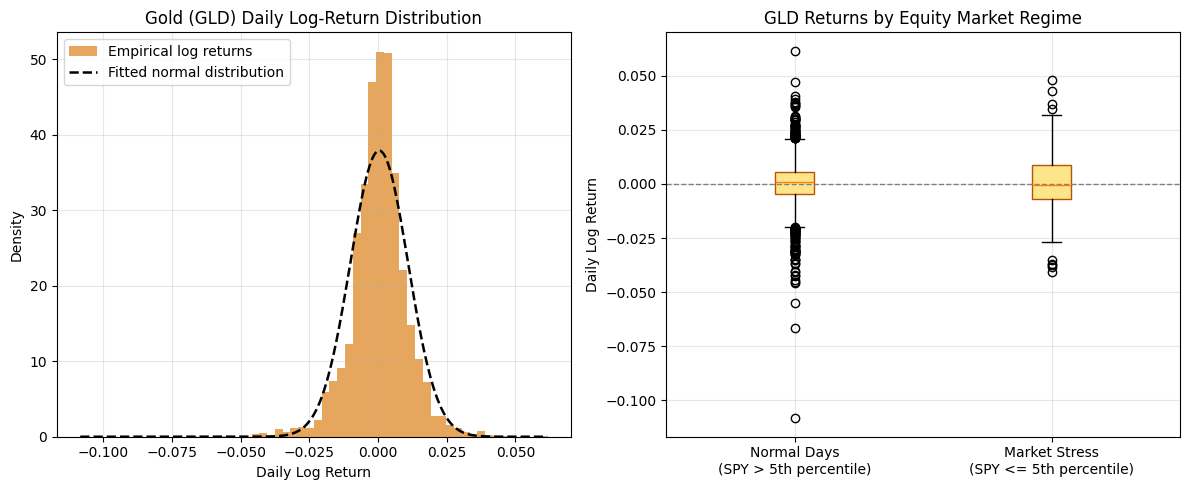

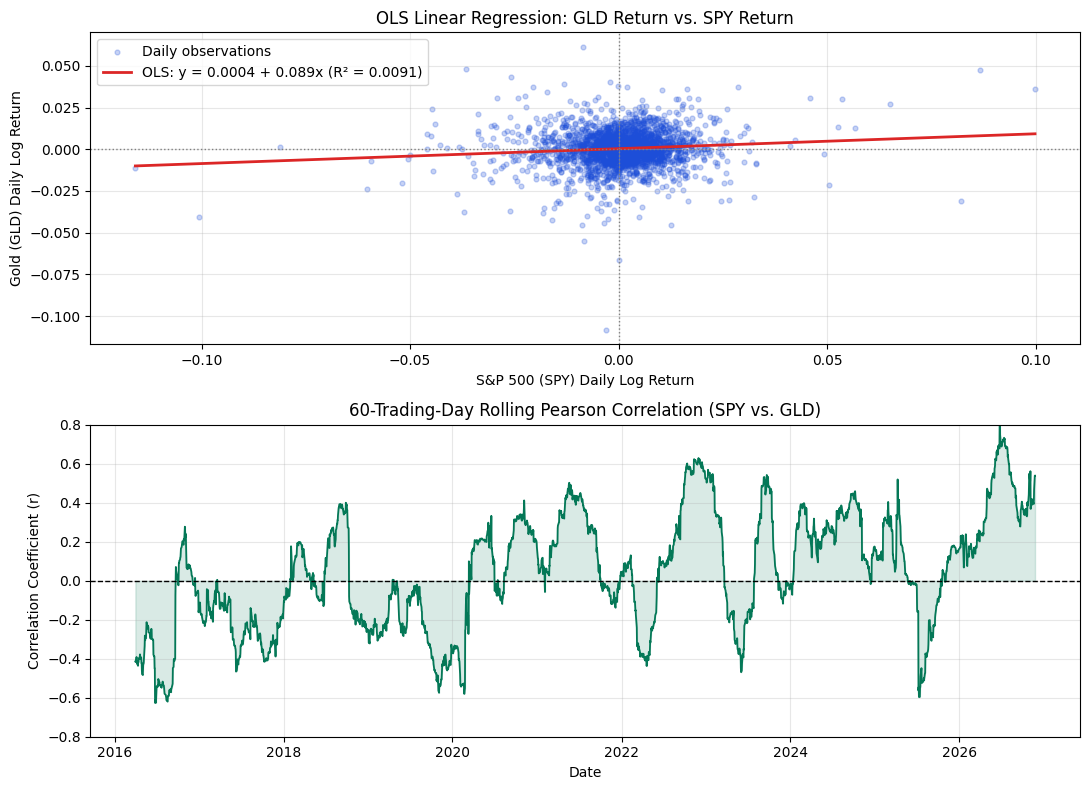

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import yfinance as yf

# 1. Load data (automatically downloads if market_data.csv is not in the local Colab environment)
try:
    df = pd.read_csv("market_data.csv", index_col=0, parse_dates=True)
except FileNotFoundError:
    raw = yf.download(["SPY", "GLD"], start="2016-01-01", end="2026-11-25", auto_adjust=True)
    df = raw["Close"].dropna()
    df.columns = ["GLD_Close", "SPY_Close"]

# Compute daily log returns: r_t = ln(P_t / P_{t-1})
df["GLD_ret"] = np.log(df["GLD_Close"] / df["GLD_Close"].shift(1))
df["SPY_ret"] = np.log(df["SPY_Close"] / df["SPY_Close"].shift(1))
df = df.dropna()

# ==============================================================================
# ANALYSIS 1: Distribution Check & Hypothesis Testing (Safe Haven Test)
# ==============================================================================
jb_spy = stats.jarque_bera(df["SPY_ret"])
jb_gld = stats.jarque_bera(df["GLD_ret"])

# Market stress days: worst 5% daily returns of the S&P 500
stress_threshold = df["SPY_ret"].quantile(0.05)
stress_days = df[df["SPY_ret"] <= stress_threshold]["GLD_ret"]
normal_days = df[df["SPY_ret"] > stress_threshold]["GLD_ret"]

# Two-sample Welch's t-test and non-parametric Mann-Whitney U test
t_stat, p_val_t = stats.ttest_ind(stress_days, normal_days, equal_var=False)
u_stat, p_val_u = stats.mannwhitneyu(stress_days, normal_days, alternative="two-sided")

print("=== ANALYSIS 1: DISTRIBUTION & HYPOTHESIS TESTING ===")
print(f"Total observations: {len(df)} trading days")
print(f"Jarque-Bera normality test p-value (SPY): {jb_spy.pvalue:.4e} | (GLD): {jb_gld.pvalue:.4e}")
print(f"S&P 500 stress threshold (bottom 5%): {stress_threshold*100:.2f}%")
print(f"GLD mean daily return on stress days (n={len(stress_days)}): {stress_days.mean()*100:.4f}%")
print(f"GLD mean daily return on normal days (n={len(normal_days)}): {normal_days.mean()*100:.4f}%")
print(f"Welch's t-test: t = {t_stat:.4f}, p = {p_val_t:.4f}")
print(f"Mann-Whitney U test: U = {u_stat:.1f}, p = {p_val_u:.4f}\n")

# ==============================================================================
# ANALYSIS 2: OLS Linear Regression & 60-Day Rolling Correlation
# ==============================================================================
reg = stats.linregress(df["SPY_ret"], df["GLD_ret"])
df["rolling_corr_60d"] = df["SPY_ret"].rolling(window=60).corr(df["GLD_ret"])

print("=== ANALYSIS 2: OLS REGRESSION & ROLLING CORRELATION ===")
print(f"Regression equation: r_GLD = {reg.intercept:.5f} + {reg.slope:.4f} * r_SPY")
print(f"Correlation (r): {reg.rvalue:.4f} | R-squared: {reg.rvalue**2:.4f} | p-value: {reg.pvalue:.4f}")
print(f"60-day rolling correlation -> Min: {df['rolling_corr_60d'].min():.3f}, "
      f"Max: {df['rolling_corr_60d'].max():.3f}, Mean: {df['rolling_corr_60d'].mean():.3f}")

# ==============================================================================
# GENERATE & EXPORT FIGURES (PDF for repo requirement + PNG for website)
# ==============================================================================

# Figure 1: Return Distributions (Fat Tails) + Boxplot by Market Regime
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

x_vals = np.linspace(df["GLD_ret"].min(), df["GLD_ret"].max(), 300)
norm_pdf = stats.norm.pdf(x_vals, df["GLD_ret"].mean(), df["GLD_ret"].std())
axes[0].hist(df["GLD_ret"], bins=60, density=True, alpha=0.65, color="#d97706", label="Empirical log returns")
axes[0].plot(x_vals, norm_pdf, "k--", linewidth=1.8, label="Fitted normal distribution")
axes[0].set_title("Gold (GLD) Daily Log-Return Distribution")
axes[0].set_xlabel("Daily Log Return")
axes[0].set_ylabel("Density")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].boxplot([normal_days, stress_days],
                labels=["Normal Days\n(SPY > 5th percentile)", "Market Stress\n(SPY <= 5th percentile)"],
                patch_artist=True, boxprops=dict(facecolor="#fde68a", color="#b45309"))
axes[1].axhline(0, color="gray", linestyle="--", linewidth=1)
axes[1].set_title("GLD Returns by Equity Market Regime")
axes[1].set_ylabel("Daily Log Return")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("fig1_distributions.pdf", format="pdf", bbox_inches="tight")
plt.savefig("fig1_distributions.png", format="png", dpi=200, bbox_inches="tight")
plt.show()

# Figure 2: OLS Linear Regression + 60-Day Rolling Correlation
fig, axes = plt.subplots(2, 1, figsize=(11, 8))

axes[0].scatter(df["SPY_ret"], df["GLD_ret"], alpha=0.25, s=12, color="#1d4ed8", label="Daily observations")
x_reg = np.linspace(df["SPY_ret"].min(), df["SPY_ret"].max(), 200)
y_reg = reg.intercept + reg.slope * x_reg
axes[0].plot(x_reg, y_reg, color="#dc2626", linewidth=2,
             label=f"OLS: y = {reg.intercept:.4f} + {reg.slope:.3f}x (R² = {reg.rvalue**2:.4f})")
axes[0].axhline(0, color="gray", linestyle=":", linewidth=1)
axes[0].axvline(0, color="gray", linestyle=":", linewidth=1)
axes[0].set_title("OLS Linear Regression: GLD Return vs. SPY Return")
axes[0].set_xlabel("S&P 500 (SPY) Daily Log Return")
axes[0].set_ylabel("Gold (GLD) Daily Log Return")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(df.index, df["rolling_corr_60d"], color="#047857", linewidth=1.3)
axes[1].axhline(0, color="black", linestyle="--", linewidth=1)
axes[1].fill_between(df.index, df["rolling_corr_60d"], 0, alpha=0.15, color="#047857")
axes[1].set_title("60-Trading-Day Rolling Pearson Correlation (SPY vs. GLD)")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Correlation Coefficient (r)")
axes[1].set_ylim(-0.8, 0.8)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("fig2_regression_correlation.pdf", format="pdf", bbox_inches="tight")
plt.savefig("fig2_regression_correlation.png", format="png", dpi=200, bbox_inches="tight")
plt.show()